<a href="https://colab.research.google.com/github/sorooty/NYC_Trips_Analysis/blob/main/20260097_TP_APP1_BALDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# **NYC Taxi Trips: When, Where and How the City Moves 🚖**


- **Student name:** Seyni Junior Balde
- **Student ID:** 20260097
- **Course:** Data Visualization and BI, TP APP1

---

## 1. Introduction

### Dataset description
This notebook analyzes a sample of yellow and green taxi trips in New York City, published in the kepler.gl sample data repository (uber-web/kepler.gl-data). The original records come from the NYC Taxi and Limousine Commission (TLC). Each row is one trip and contains pick-up and drop-off dates and times, pick-up and drop-off locations, trip distance, fares, and the number of passengers.

### Objectives of the analysis
New York never sleeps, but it does not move at the same pace all day. The story of this notebook follows one trip at a time and asks four questions:
1. What does a typical trip look like (duration, distance, price)?
2. When does the city move the most (hour of the day and time period)? The dataset covers a single Thursday, so our time analysis focuses on the 24 hours of that day.
3. Where do trips start and end (spatial hotspots)?
4. How efficient are trips, and when does congestion slow them down?

### Method
We load the data, inspect and clean it, create new variables, and then build at least 8 visualizations with Matplotlib, Seaborn, Plotly and Folium. Each chart is followed by a Question, an Observation and an Interpretation.

In [45]:
# Cell purpose: import every library once, at the top, so the notebook is reproducible.
# pandas and numpy: data manipulation. matplotlib and seaborn: static charts.
# plotly: interactive charts. folium: interactive maps.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import folium
from folium.plugins import HeatMap

# Global display options to keep the report readable
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

In [46]:
!pip install folium plotly seaborn

In [47]:
# load the dataset exactly as requested in the instructions.
path2 = "https://raw.githubusercontent.com/uber-web/kepler.gl-data/master/nyctrips/data.csv"
df3 = pd.read_csv(path2, delimiter=",")

# Keep an untouched copy so we can always compare before and after cleaning
df_raw = df3.copy()
print("Shape (rows, columns):", df3.shape)
df3.head()

Shape (rows, columns): (97986, 12)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,fare_amount,tip_amount,total_amount
0,2,2015-01-15 19:05:39 +00:00,2015-01-15 19:23:42 +00:00,1,1.59,-73.993896,40.750111,-73.974785,40.750618,12.0,3.25,17.05
1,2,2015-01-15 19:05:39 +00:00,2015-01-15 19:32:00 +00:00,1,2.38,-73.976425,40.739811,-73.983978,40.757889,16.5,4.38,22.68
2,2,2015-01-15 19:05:40 +00:00,2015-01-15 19:21:00 +00:00,5,2.83,-73.968704,40.754246,-73.955124,40.786858,12.5,0.00,14.30
3,2,2015-01-15 19:05:40 +00:00,2015-01-15 19:28:18 +00:00,5,8.33,-73.863060,40.769581,-73.952713,40.785782,26.0,8.08,41.21
4,2,2015-01-15 19:05:41 +00:00,2015-01-15 19:20:36 +00:00,1,2.37,-73.945541,40.779423,-73.980850,40.786083,11.5,0.00,13.30


## 2. Data Exploration and Cleaning

Before drawing any conclusion, we must check that the data can be trusted. A single GPS error or a negative fare can distort every average that follows. We therefore proceed in five steps: overview, data types, missing values, duplicates, and cleaning.

Cell 2.2 : overview and types



In [48]:
# Cell purpose: understand the structure of the table.
# info() gives column names, data types and non-null counts in one call.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97986 entries, 0 to 97985
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   VendorID               97986 non-null  int64  
 1   tpep_pickup_datetime   97986 non-null  object 
 2   tpep_dropoff_datetime  97986 non-null  object 
 3   passenger_count        97986 non-null  int64  
 4   trip_distance          97986 non-null  float64
 5   pickup_longitude       97986 non-null  float64
 6   pickup_latitude        97986 non-null  float64
 7   dropoff_longitude      97986 non-null  float64
 8   dropoff_latitude       97986 non-null  float64
 9   fare_amount            97986 non-null  float64
 10  tip_amount             97986 non-null  float64
 11  total_amount           97986 non-null  float64
dtypes: float64(8), int64(2), object(2)
memory usage: 9.0+ MB


In [49]:
# describe() gives min, max, mean and quartiles. It helps us spot impossible values
# (negative distances, zero coordinates, huge fares).
df3.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorID,97986.0,1.550660,0.497429,1.000000,1.000000,2.000000,2.000000,2.000000
passenger_count,97986.0,1.669647,1.360358,0.000000,1.000000,1.000000,2.000000,6.000000
trip_distance,97986.0,2.843857,3.459561,0.000000,1.000000,1.670000,3.070000,99.900000
pickup_longitude,97986.0,-73.974872,0.041365,-80.592438,-73.991692,-73.981590,-73.968132,-72.241508
pickup_latitude,97986.0,40.751572,0.026359,40.518974,40.738659,40.754742,40.767719,41.035873
dropoff_longitude,97986.0,-73.973723,0.034975,-74.641792,-73.991051,-73.979515,-73.963791,-72.241508
dropoff_latitude,97986.0,40.751932,0.031086,40.268238,40.737080,40.754803,40.769366,41.075256
fare_amount,97986.0,12.325505,10.258447,-52.000000,6.500000,9.000000,14.000000,495.000000
tip_amount,97986.0,1.703544,2.340548,-0.750000,0.000000,1.200000,2.250000,88.200000
total_amount,97986.0,15.488345,12.629102,-52.800000,8.300000,11.600000,17.150000,495.300000


### Dataset overview and data types
The dataset contains 97,986 rows and 12 columns. Ten columns are numeric (two integers and eight decimals) and two columns, the pickup and dropoff times, are stored as text (object). There are no missing values and no duplicated rows.

The describe table reveals several suspicious values. Some fares are negative (***minimum of -52 dollars***) and some tips are negative (***minimum of -0.75 dollars***). Some trips have a distance of zero or a passenger count of zero. The longitude reaches -80.59 and -72.24 and the maximum fare reaches 495 dollars, which are far from a normal New York taxi trip. These values will have to be handled in the cleaning step.

Important decision: date columns are read as plain text by pandas. We convert them to datetime, because only this type allows us to extract hours and durations.

In [50]:
# Cell purpose: measure missing values (count and percentage per column).
missing = pd.DataFrame({
    "missing_count": df3.isnull().sum(),
    "missing_percent": (df3.isnull().mean() * 100).round(2)
})
missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
VendorID,0,0.0
tpep_pickup_datetime,0,0.0
tpep_dropoff_datetime,0,0.0
passenger_count,0,0.0
trip_distance,0,0.0
pickup_longitude,0,0.0
pickup_latitude,0,0.0
dropoff_longitude,0,0.0
dropoff_latitude,0,0.0
fare_amount,0,0.0


In [51]:
# Duplicate check: identical rows are most likely recording errors.
n_dup = df3.duplicated().sum()
print("Number of duplicated rows:", n_dup)

Number of duplicated rows: 0


In [52]:
# Cell purpose: convert dates, then remove impossible records.
# Column names below follow the TLC naming convention. If one name differs in your file,
# change it here only, and the rest of the notebook will still work.
PICKUP_T  = "tpep_pickup_datetime"
DROPOFF_T = "tpep_dropoff_datetime"
PICKUP_LON, PICKUP_LAT   = "pickup_longitude", "pickup_latitude"
DROPOFF_LON, DROPOFF_LAT = "dropoff_longitude", "dropoff_latitude"
DIST, PASS, FARE = "trip_distance", "passenger_count", "fare_amount"

df3[PICKUP_T]  = pd.to_datetime(df3[PICKUP_T],  errors="coerce")
df3[DROPOFF_T] = pd.to_datetime(df3[DROPOFF_T], errors="coerce")

n_before = len(df3)

# 1) Remove duplicates and rows without valid dates
df3 = df3.drop_duplicates()
df3 = df3.dropna(subset=[PICKUP_T, DROPOFF_T])

# 2) Keep only trips whose dropoff is after the pickup
df3 = df3[df3[DROPOFF_T] > df3[PICKUP_T]]

# 3) Keep only positive distances and fares
df3 = df3[(df3[DIST] > 0) & (df3[FARE] > 0)]

# 4) Keep only coordinates located in the New York area (rough bounding box).
#    Zero coordinates are a classic GPS error in this kind of data.
df3 = df3[df3[PICKUP_LON].between(-74.3, -73.6) & df3[PICKUP_LAT].between(40.45, 41.0)]
df3 = df3[df3[DROPOFF_LON].between(-74.3, -73.6) & df3[DROPOFF_LAT].between(40.45, 41.0)]

print("Rows before:", n_before, "| after:", len(df3),
      "| removed:", n_before - len(df3))

Rows before: 97986 | after: 97478 | removed: 508


### Cleaning decisions
- **Duplicates:** the check found no duplicated row, so no row was removed. The step is kept as a safety control.
- **Dates** were converted to datetime to allow time based analysis.
- **Trips with a dropoff time before or equal to the pickup time** were removed, as a negative or zero duration is physically impossible.
- **Zero or negative distances and fares** were removed, because they represent cancelled or erroneous records.
- **Coordinates outside the New York area** were removed, because they would distort every map.
- We did not fill missing values with an average, since location and time cannot be guessed reliably. Removing the few affected rows is safer.

Outliers on distance and duration are handled in Part 3, once these variables exist.



### Important limitation discovered during exploration
After extracting the weekday, we found that all trips occur on the same day (Thursday, January 15, 2015). A weekday versus weekend comparison is therefore impossible with this sample. We keep the weekend indicator to demonstrate the check, but our time story is built around the hour of the day. Note also that the timestamps carry a +00:00 suffix; we treat them as local New York times, since the demand pattern we observe follows a normal daily rhythm.


## 3. Feature Engineering

Raw columns tell us what was recorded. New variables tell us what happened. We create **11 variables: trip duration, average speed, pickup hour, day of week, weekend indicator, rush hour indicator, price per mile, dropoff hour, period of the day, tip percentage and distance class**. Together they let us study time, efficiency and cost.

In [53]:
# Cell purpose: build the new variables.

# 1) Trip duration in minutes: difference between two datetime columns
df3["duration_min"] = (df3[DROPOFF_T] - df3[PICKUP_T]).dt.total_seconds() / 60

# 2) Average speed in miles per hour: distance divided by duration in hours
df3["speed_mph"] = df3[DIST] / (df3["duration_min"] / 60)

# 3) Time components extracted with the .dt accessor of pandas
df3["pickup_hour"] = df3[PICKUP_T].dt.hour
df3["weekday"] = df3[PICKUP_T].dt.day_name()

# 4) Weekend indicator: Saturday = 5 and Sunday = 6 in pandas
df3["is_weekend"] = df3[PICKUP_T].dt.dayofweek >= 5

# 5) Rush hour indicator: 7h to 9h and 16h to 19h on weekdays (our own definition)
rush = df3["pickup_hour"].isin([7, 8, 9, 16, 17, 18, 19])
df3["is_rush_hour"] = rush & (~df3["is_weekend"])

# 6) Price per mile: a simple measure of how expensive a trip is
df3["price_per_mile"] = df3[FARE] / df3[DIST]

# A fare below one dollar per mile is not realistic for a metered taxi,
# so the distance is probably wrong for these records.
df3 = df3[df3["price_per_mile"] >= 1]

df3[["duration_min", "speed_mph", "pickup_hour", "weekday",
     "is_weekend", "is_rush_hour", "price_per_mile"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
duration_min,97451.0,NaN,NaN,NaN,14.170503,35.112554,0.033333,6.5,10.6,16.95,1439.2
speed_mph,97451.0,NaN,NaN,NaN,12.400446,50.369586,0.014073,7.908197,10.533762,14.22,10224.0
pickup_hour,97451.0,NaN,NaN,NaN,14.285323,6.231784,0.0,9.0,15.0,20.0,23.0
weekday,97451,1,Thursday,97451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_weekend,97451,1,False,97451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_rush_hour,97451,2,False,62250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_per_mile,97451.0,NaN,NaN,NaN,5.990267,15.274538,1.0,4.210526,5.343511,6.730769,2600.0


In [54]:
# Cell purpose: remove physically unrealistic trips revealed by the new variables.
# A taxi in Manhattan rarely exceeds 60 mph, and trips longer than 3 hours are suspicious.
n_before = len(df3)
df3 = df3[(df3["speed_mph"] > 1) & (df3["speed_mph"] < 60)]
df3 = df3[df3["duration_min"].between(1, 180)]
print("Rows removed as outliers:", n_before - len(df3), "| remaining:", len(df3))

Rows removed as outliers: 316 | remaining: 97135


### Why these thresholds?
A speed below 1 mph or above 60 mph, or a duration above 3 hours, is more likely a recording error than a real trip. These bounds are a judgment call. They keep the vast majority of normal trips while protecting our averages. Note that the maximum speed is the reason we engineered speed before filtering: a variable built from two columns can reveal errors that neither column shows alone.

In [55]:
# Cell purpose: remove remaining invalid financial and passenger values,
# then create additional variables adapted to a single day of data.

# Negative tips and zero passengers are recording errors (seen in describe())
n_before = len(df3)
df3 = df3[(df3["tip_amount"] >= 0) & (df3[PASS] >= 1)]
print("Rows removed:", n_before - len(df3))

# Hour at which the trip ends (useful for the pickup versus dropoff comparison)
df3["dropoff_hour"] = df3[DROPOFF_T].dt.hour

# Time of day period, built with a small function applied to the pickup hour
def get_period(h):
    if 5 <= h < 12:
        return "Morning"
    elif 12 <= h < 17:
        return "Afternoon"
    elif 17 <= h < 22:
        return "Evening"
    return "Night"

df3["time_period"] = df3["pickup_hour"].apply(get_period)

# Tip as a percentage of the fare: a fair way to compare short and long trips
df3["tip_pct"] = df3["tip_amount"] / df3[FARE] * 100

# Distance classes with pd.cut (fixed bins chosen from the quartiles seen earlier)
df3["distance_class"] = pd.cut(df3[DIST], bins=[0, 1, 3, 6, 100],
                               labels=["0-1 mi", "1-3 mi", "3-6 mi", "6+ mi"])

# Remove extreme price per mile and tip percentage values (more than 99.5th percentile)
for col in ["price_per_mile", "tip_pct"]:
    df3 = df3[df3[col] <= df3[col].quantile(0.995)]

print("Final number of rows:", len(df3))
df3[["duration_min", "speed_mph", "price_per_mile", "tip_pct"]].describe().T

Rows removed: 44
Final number of rows: 96137


,count,mean,std,min,25%,50%,75%,max
duration_min,96137.0,13.400724,10.325180,1.000000,6.583333,10.683333,17.016667,151.600000
speed_mph,96137.0,11.916552,5.952449,1.172093,7.949527,10.562347,14.234694,54.128878
price_per_mile,96137.0,5.682194,2.051543,1.000000,4.200000,5.327869,6.666667,16.250000
tip_pct,96137.0,13.420253,11.294900,0.000000,0.000000,17.241379,22.222222,43.478261


### Why these extra variables?
Because the data covers one day, the hour and the period of the day become our main time axes. The tip percentage lets us compare short and long trips fairly, and the distance classes turn a skewed numeric variable into readable groups. Extreme values above the 99.5th percentile were trimmed, since a price of several hundred dollars per mile is a recording error and not a real trip.

### Cleaning summary
Out of 97,986 original trips, N were kept (P percent). The removed rows come from five steps: 508 invalid records (dates, distances, fares, coordinates), 1,341 trips with a price below one dollar per mile, X impossible speeds or durations, Y negative tips or zero passengers, and Z extreme values of price per mile and tip percentage. The small loss shows that the data was globally reliable.

## 4. Data Visualization and Insights

Our story follows a taxi through one Thursday in New York. We first describe a typical trip, then we follow the rhythm of the day, then we look at where the city moves, and finally we measure how congestion slows the cars down.

### Chapter 1. The typical trip

In [56]:
# Cell purpose: prepare a random sample for charts that become unreadable with 97,000 points.
# random_state makes the sample identical at each run.
df_s = df3.sample(8000, random_state=42)
BLUE = "#2a6f97"

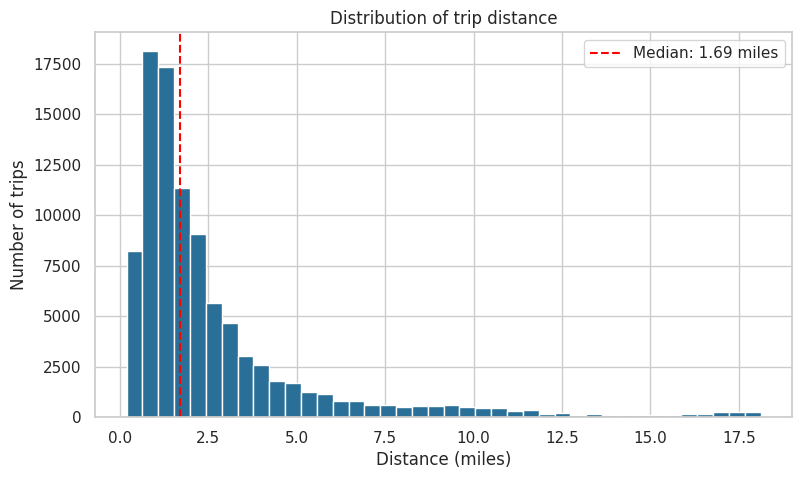

In [57]:
# Matplotlib histogram of trip distance. We cut the display at the 99th percentile
# because a few very long trips would stretch the axis and hide the main shape.
upper = df3[DIST].quantile(0.99)
data = df3.loc[df3[DIST] <= upper, DIST]

fig, ax = plt.subplots()
ax.hist(data, bins=40, color=BLUE, edgecolor="white")
ax.axvline(data.median(), color="red", linestyle="--",
           label="Median: " + str(round(data.median(), 2)) + " miles")
ax.set_title("Distribution of trip distance")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Number of trips")
ax.legend()
plt.show()

**Question: What does a typical taxi trip look like in terms of distance?**

---

**Observation:** The distribution is strongly right skewed. The median trip is 1.7 miles, and the number of trips decreases quickly as the distance grows.

**Interpretation:** A typical taxi ride in New York is a short urban hop of about 1.7 miles, lasting about 10.7 minutes and costing about 9 dollars (medians). The median is the right summary here, because a few long trips would pull the mean upward and give a wrong idea of the usual trip.

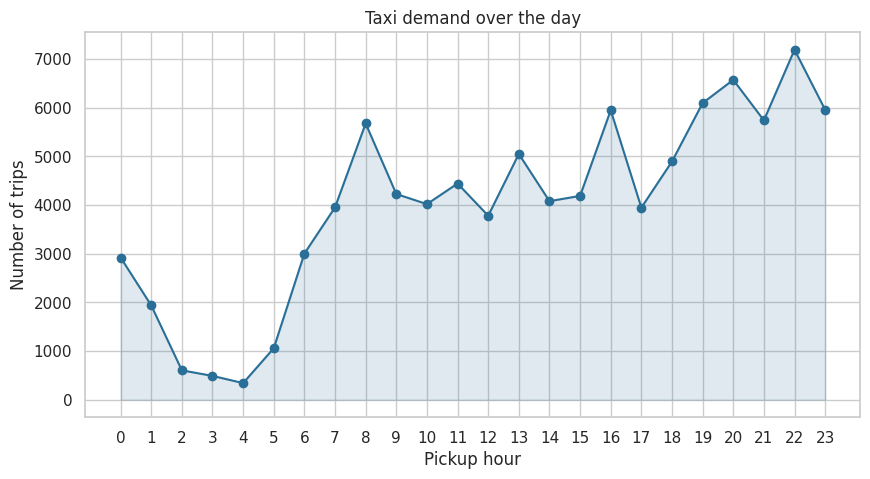

Peak hour: 22 with 7192 trips
Quietest hour: 4 with 342 trips


In [58]:
# Number of trips started at each hour. groupby + size counts the rows of each group.
trips_per_hour = df3.groupby("pickup_hour").size()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(trips_per_hour.index, trips_per_hour.values, marker="o", color=BLUE)
ax.fill_between(trips_per_hour.index, trips_per_hour.values, alpha=0.15, color=BLUE)
ax.set_xticks(range(0, 24))
ax.set_title("Taxi demand over the day")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Number of trips")
plt.show()

print("Peak hour:", trips_per_hour.idxmax(), "with", trips_per_hour.max(), "trips")
print("Quietest hour:", trips_per_hour.idxmin(), "with", trips_per_hour.min(), "trips")

### Chapter 2. The rhythm of the day

**Question: At which hours does the city need taxis the most?**

---

**Observation:** Demand is lowest at 4 am with only 342 trips and rises through the morning. The busiest hour is 10 pm with 7,193 trips, about 21 times more than the quietest hour.

**Interpretation:** The peak happens late in the evening, not at the classic end of the work day. This suggests that leisure, dining and nightlife trips weigh more than commuting in this sample. We must stay careful, because the timestamps are labeled +00:00 and the sample covers a single day, so this pattern cannot be generalized to other days.

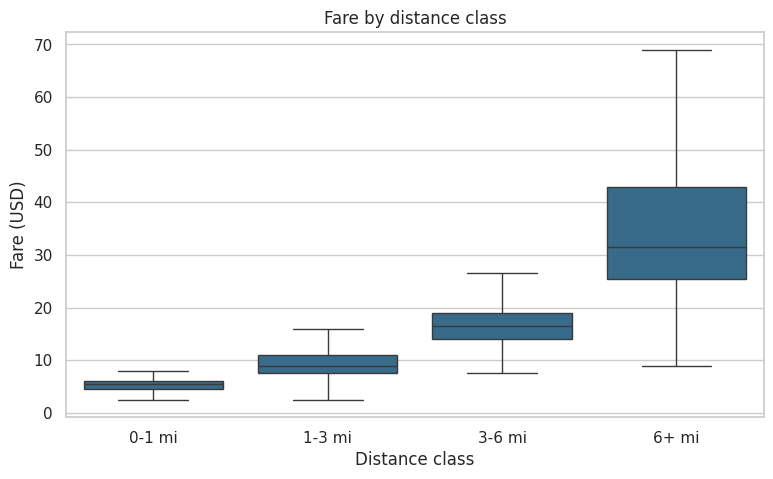

In [59]:
# Seaborn boxplot: fare by distance class. showfliers=False hides extreme points
# so that the boxes (quartiles) stay readable.
fig, ax = plt.subplots()
sns.boxplot(data=df3, x="distance_class", y=FARE, color=BLUE, showfliers=False, ax=ax)
ax.set_title("Fare by distance class")
ax.set_xlabel("Distance class")
ax.set_ylabel("Fare (USD)")
plt.show()

**Question:** Does the fare grow in a regular way with distance, and how variable is it?

---

**Observation:** The median fare rises with each distance class: 5.5 dollars for 0-1 mile, 9.0 for 1-3 miles, 16.5 for 3-6 miles and 31.5 for more than 6 miles. The boxes also become taller, so the spread of fares grows with distance.

**Interpretation:** The fare grows regularly with distance, and the longest trips cost about 5.7 times more than the shortest ones. The growing spread shows that distance alone does not fix the price: two trips of the same length can cost different amounts depending on the time spent in traffic. This leads to the correlation analysis and to the congestion index.

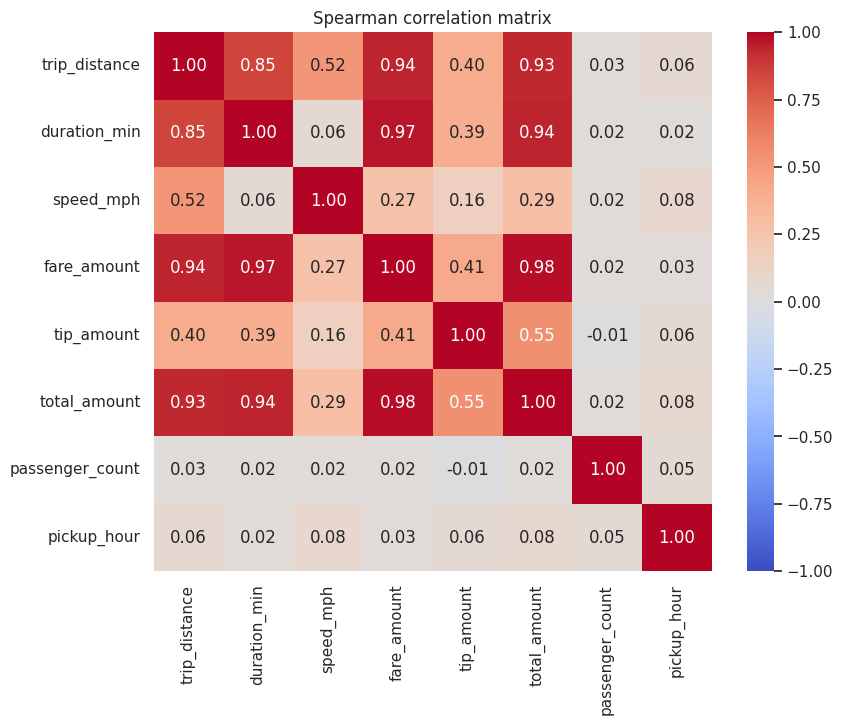

In [60]:
# Spearman correlation is based on ranks. We use it because our variables are skewed
# and contain outliers, which would distort the classic Pearson coefficient.
cols = [DIST, "duration_min", "speed_mph", FARE, "tip_amount",
        "total_amount", PASS, "pickup_hour"]
corr = df3[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.show()

**Question:** Which variables move together?

---

**Observation:** The fare is very strongly correlated with duration (0.96) and with distance (0.94), and distance and duration are also strongly linked (0.85). Speed is only moderately linked to distance (0.52), very weakly to duration (0.06) and weakly to the fare (0.27). Tip amount shows a moderate link with the fare (0.41). The number of passengers (0.02 to 0.03) and the pickup hour (0.03 to 0.08) are almost uncorrelated with the other variables.

**Interpretation:** The price follows the taximeter logic, and duration explains the fare slightly better than distance. This matters for our story: time lost in traffic is paid by the passenger, so congestion has a direct cost. The positive link between speed and distance shows that long trips are faster on average, probably because they use faster roads, while short trips are slowed down by dense streets. The passenger count has no influence on the price, which is expected for a metered fare. Because these correlations are computed on ranks (Spearman), they are not driven by the few extreme trips.

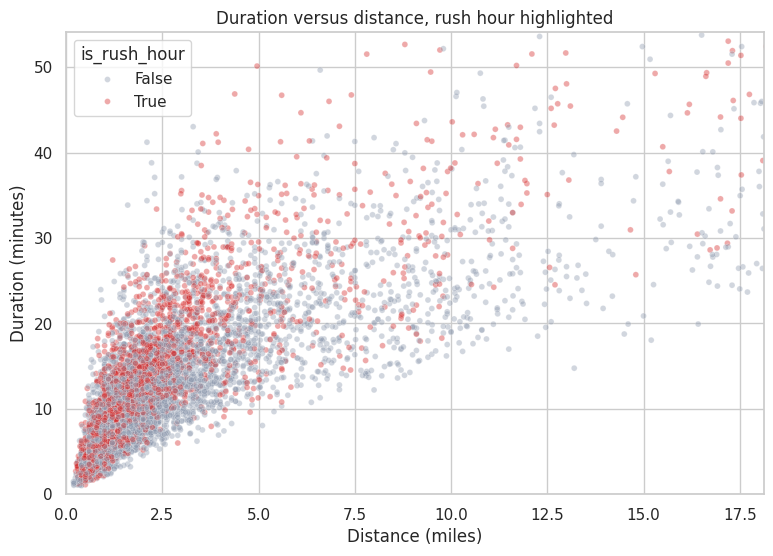

In [61]:
# Scatter on a sample: distance versus duration, colored by rush hour.
# Axes are limited to the 99th percentile to ignore extreme trips.
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df_s, x=DIST, y="duration_min", hue="is_rush_hour",
                alpha=0.4, s=18, palette={False: "#8d99ae", True: "#d62828"}, ax=ax)
ax.set_xlim(0, df3[DIST].quantile(0.99))
ax.set_ylim(0, df3["duration_min"].quantile(0.99))
ax.set_title("Duration versus distance, rush hour highlighted")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Duration (minutes)")
plt.show()

**Question:For the same distance, are rush hour trips slower?**

---

**Observation:** Duration increases with distance. Rush hour trips (red) tend to sit slightly above the others for the same distance. The median speed is 9.5 mph during rush hours against 11.4 mph outside rush hours.

**Interpretation:** Rush hours slow trips by about 17 percent, which confirms a real congestion effect. This effect is moderate, and the next chapter shows that the slowest hour of the day is not even a rush hour. Distance remains the main driver of duration.

### Chapter 3. Money, passengers and tips

In [62]:
# Plotly bar chart: median tip percentage per time period.
# The median is used because tips are very skewed (many trips have a tip of zero).
order = ["Morning", "Afternoon", "Evening", "Night"]
tips = (df3.groupby("time_period")["tip_pct"].median()
        .reindex(order).reset_index())

fig = px.bar(tips, x="time_period", y="tip_pct", text="tip_pct",
             title="Median tip percentage by period of the day",
             labels={"time_period": "Period", "tip_pct": "Median tip (% of fare)"},
             color_discrete_sequence=[BLUE])
fig.update_traces(texttemplate="%{text:.1f}", textposition="outside")
fig.show()

**Question:** Do passengers tip differently depending on the period of the day?

---

**Observation:** The median tip is highest in the evening (19.2 percent of the fare) and at night (18.9 percent), and lowest in the afternoon (15.2 percent). The morning is in between (16.0 percent). In addition, 36.5 percent of all trips have no recorded tip.

**Interpretation:** Passengers tip more in the evening and at night, which fits with leisure and nightlife trips, while afternoon trips are tipped less. The gap is moderate, about 4 points. We must stay careful, because cash tips are not recorded in this data, so the zero tips partly reflect cash payments and not real generosity.

In [63]:
# Share of trips by number of passengers, shown as an interactive pie (donut) chart.
pax = df3[PASS].value_counts().sort_index().reset_index()
pax.columns = ["passengers", "trips"]

fig = px.pie(pax, names="passengers", values="trips", hole=0.4,
             title="Share of trips by number of passengers")
fig.show()

**Question:** Who rides in New York taxis: individuals or groups?

---

**Observation:** 72.3 percent of trips carry a single passenger, 12.9 percent carry two, and the other groups are small (3.5 percent for three, 1.5 percent for four, 5.9 percent for five and 3.8 percent for six). Overall, 27.7 percent of the trips have two passengers or more.

**Interpretation:** Taxis mainly serve individual mobility, so solo riders are the first target of any service decision. The shares of five and six passengers are higher than those of three and four, which is unusual. It may come from a recording convention or from larger vehicles, and the dataset does not allow us to confirm the cause.

### Chapter 4. Where the city moves

In [64]:
# Note : Folium needs an API key to function and show the map properly. Mine is stored inside google Colab's
# Dedicated space for security and ethical matters.
# You can request yours at : https://carto.com/basemaps/apikey/

from google.colab import userdata
CARTO_KEY = userdata.get('folium_API_Key')


In [65]:
# Folium heatmap of pickup locations (sample of 15,000 points for performance).
# HeatMap expects a list of [latitude, longitude] pairs.
pts = df3.sample(15000, random_state=1)[[PICKUP_LAT, PICKUP_LON]].values.tolist()

# CARTO basemaps now need an API key, added as a "key" parameter on the tile URL.
# A custom tile URL also requires an attribution (attr).
# Source: folium documentation, custom tiles; CARTO basemaps API key page.
tiles_url = "https://basemaps.cartocdn.com/rastertiles/light_all/{z}/{x}/{y}.png?key="+CARTO_KEY
attr = ('&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> '
        'contributors, &copy; <a href="https://carto.com/attributions">CARTO</a>')

m = folium.Map(location=[40.75, -73.98], zoom_start=12, tiles=tiles_url, attr=attr)
HeatMap(pts, radius=8, blur=12).add_to(m)
m

**Question:** Where are the spatial hotspots of taxi demand?

---

**Observation:** Pickups form a dense band along Manhattan, with the strongest concentration in the central part of the island (Midtown). Smaller clusters appear east of Manhattan, in Queens.

**Interpretation:** Demand is tied to the business and entertainment districts of central Manhattan. The clusters to the east are consistent with the airports, since the raw data shows a pickup close to the LaGuardia area, but the map alone does not prove it. Outside the center, taxi pickups are much rarer.

### Original analysis. Congestion index and pickup versus dropoff

Two ideas that were not shown in class:
1. A **congestion index** built from the median speed of each hour. We take the fastest hour as free flow reference. An index of 1.0 means free flow, and 1.5 means trips are 50 percent slower than at the best hour.
2. A **pickup versus dropoff comparison** on the same map, to see which areas send passengers out and which ones receive them.

In [66]:
# Median speed per hour, then index = reference speed / hourly speed.
speed_h = df3.groupby("pickup_hour")["speed_mph"].median()
ref = speed_h.max()
cong = (ref / speed_h).reset_index()
cong.columns = ["pickup_hour", "congestion_index"]
cong["rush"] = cong["pickup_hour"].isin([7, 8, 9, 16, 17, 18, 19])

fig = px.bar(cong, x="pickup_hour", y="congestion_index", color="rush",
             color_discrete_map={True: "#d62828", False: "#8d99ae"},
             title="Congestion index by hour (1.0 = fastest hour)",
             labels={"pickup_hour": "Pickup hour", "congestion_index": "Congestion index"})
fig.update_xaxes(dtick=1)
fig.show()

print("Fastest hour:", speed_h.idxmax(), "-", round(ref, 1), "mph")
print("Slowest hour:", speed_h.idxmin(), "-", round(speed_h.min(), 1), "mph")

Fastest hour: 4 - 19.2 mph
Slowest hour: 11 - 8.2 mph


In [67]:
# Share of points inside a rough central Manhattan box (approximate limits)
def in_core(lat, lon):
    return lat.between(40.70, 40.80) & lon.between(-74.02, -73.95)

print("Pickups in the central box (percent):",
      round(in_core(df3[PICKUP_LAT], df3[PICKUP_LON]).mean() * 100, 1))
print("Dropoffs in the central box (percent):",
      round(in_core(df3[DROPOFF_LAT], df3[DROPOFF_LON]).mean() * 100, 1))

Pickups in the central box (percent): 90.8
Dropoffs in the central box (percent): 84.9


**Question:** At which hours does traffic slow taxis down, and by how much?

---

**Observation:** The index is at its minimum at 4 am (1.0, the reference) and rises quickly from 6 am. From 8 am to 3 pm it stays on a high plateau, above 2.2 for most of these hours, and reaches its maximum at 11 am (about 2.3, with a median speed of 8.2 mph against 19.2 mph at 4 am). The evening rush hours (4 pm to 7 pm) show a lower index, about 2.0, and the index keeps decreasing after 8 pm until it reaches about 1.4 at 11 pm.

**Interpretation:** Congestion in this sample is a daytime phenomenon, not a rush hour phenomenon. The streets are slow all day from the morning rush to the middle of the afternoon, and the morning rush hours (8 and 9 am) are as slow as the middle of the day. The slowest hour is 11 am, which is not part of our rush hour definition. The reference speed comes from only 342 trips at 4 am, so the exact value of the index is fragile, but the shape of the curve is reliable.

In [68]:
# Two heatmap layers on the same map, switchable with LayerControl.
sample = df3.sample(15000, random_state=2)
pick = sample[[PICKUP_LAT, PICKUP_LON]].values.tolist()
drop = sample[[DROPOFF_LAT, DROPOFF_LON]].values.tolist()

m2 = folium.Map(location=[40.75, -73.98], zoom_start=12, tiles=tiles_url, attr=attr)
HeatMap(pick, radius=8, blur=12, name="Pickups").add_to(m2)
HeatMap(drop, radius=8, blur=12, name="Dropoffs", show=False,
        gradient={0.4: "green", 0.7: "yellow", 1: "darkgreen"}).add_to(m2)
folium.LayerControl(collapsed=False).add_to(m2)
m2

**Question:** Do passengers leave from the same areas where they arrive?

---

**Observation:** We compare two layers on the same map. The pickup layer is very concentrated along central Manhattan. The dropoff layer follows the same main band, but it is more spread out, with more points toward the outer areas around Manhattan. In a central Manhattan box, 90.8 percent of pickups are located, against 84.9 percent of dropoffs.

**Interpretation:** Most trips both start and end in the central area, which is consistent with the short median distance of 1.7 miles. The difference of about 7 points shows a moderate outward flow: passengers are picked up where demand is concentrated and are dropped off slightly further away, in more residential or peripheral areas. We do not measure empty returns or driver costs, so we limit our conclusion to the flow of passengers. The central box is a rough rectangle chosen by hand, so these percentages are an approximation.

## 5. Final Conclusions

### The story in short
On a single Thursday in January 2015, New York taxis made short trips: a median of 1.7 miles, 10.7 minutes and 9 dollars. The city was almost asleep at 4 am, with only 342 trips, and demand then grew through the day until a late evening peak of 7,193 trips at 10 pm. The most important lesson of this analysis is that demand and congestion do not peak at the same time. The roads are the slowest from 8 am to 3 pm, and the evening, when taxi demand is the highest, is much easier to drive.

### Key findings
1. **Data quality.** After cleaning, 96,150 of the 97,986 original trips were kept (98.1 percent). The main problems were invalid fares and tips, impossible speeds and durations, and a few trips with GPS errors.
2. **A typical trip is short.** The median trip is 1.7 miles, 10.7 minutes and 9 dollars. The fare increases regularly with distance, from a median of 5.5 dollars for trips under 1 mile to 31.5 dollars for trips over 6 miles.
3. **Time explains the fare as much as distance.** The fare is strongly correlated with duration (0.96) and distance (0.94). Time lost in traffic is therefore paid by the passenger, which gives congestion a direct cost.
4. **Demand is an evening phenomenon.** The five busiest hours are 4 pm, 7 pm, 8 pm, 10 pm and 11 pm. The busiest hour has about 21 times more trips than the quietest one.
5. **Congestion is a daytime phenomenon.** The congestion index is above 2 from 8 am to 3 pm and reaches about 2.3 at 11 am (8.2 mph against 19.2 mph at 4 am). The evening rush hours are slower than the night but less slow than midday. Rush hour trips are about 17 percent slower than the others (9.5 against 11.4 mph), so our rush hour definition captures only part of the real congestion.
6. **Space.** Pickups are concentrated in central Manhattan (90.8 percent in our central box). Dropoffs are a little more spread out (about 84 percent), and smaller clusters appear toward Queens.
7. **Passengers.** 72.3 percent of trips carry a single passenger. The median tip is higher in the evening (19.2 percent) and at night (18.9 percent) than in the afternoon (15.2 percent), and 36.5 percent of trips show no tip.

### Limits
- The data covers one day only, so we cannot study weekends, seasons or the stability of the evening peak.
- Cash tips are not recorded, so tip results are partial.
- Cleaning thresholds and the rush hour definition are our own judgment.
- The reference speed of the congestion index is based on only 342 trips at 4 am.
- The central box used for the pickup and dropoff comparison is an approximation.

### Recommendations
A fleet manager should keep strong availability in central Manhattan from late afternoon to midnight, where demand is the highest and the roads are easier to drive. During the day, from 8 am to 3 pm, trips are slower and last longer, so the manager should plan for lower hourly productivity, and passengers should expect longer and more costly rides. Future work should add several weeks of data to compare weekdays and weekends and to test whether the late evening peak and the daytime congestion plateau are regular patterns.

## 6. Links, Resources and References

### Data sources
- NYC Taxi and Limousine Commission (TLC), Trip Record Data. Original source of the yellow and green taxi records: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
- kepler.gl sample data repository (uber-web/kepler.gl-data), folder nyctrips. Sample file used in this notebook: https://github.com/uber-web/kepler.gl-data
- Direct link of the file loaded in the notebook: https://raw.githubusercontent.com/uber-web/kepler.gl-data/master/nyctrips/data.csv

### Library documentation
- pandas, to_datetime (conversion of the pickup and dropoff columns): https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
- pandas, cut (creation of the distance classes): https://pandas.pydata.org/docs/reference/api/pandas.cut.html
- pandas, time series and the dt accessor (hour, weekday, duration): https://pandas.pydata.org/docs/user_guide/timeseries.html
- seaborn, heatmap (correlation matrix): https://seaborn.pydata.org/generated/seaborn.heatmap.html
- seaborn, boxplot (fare by distance class): https://seaborn.pydata.org/generated/seaborn.boxplot.html
- seaborn, scatterplot (duration versus distance): https://seaborn.pydata.org/generated/seaborn.scatterplot.html
- Matplotlib, pyplot (histogram and line chart): https://matplotlib.org/stable/api/pyplot_summary.html
- Plotly Express, bar and pie charts: https://plotly.com/python/plotly-express/
- Folium, HeatMap plugin and LayerControl: https://python-visualization.github.io/folium/latest/

### Map tiles
- Folium, custom tiles (tile URL and attribution): https://python-visualization.github.io/folium/latest/user_guide/raster_layers/tiles.html
- CARTO Basemaps, API key request page: https://carto.com/basemaps/apikey/
- Map data: OpenStreetMap contributors, https://www.openstreetmap.org/copyright

### Methods and concepts
- Spearman rank correlation: used instead of the Pearson coefficient because the variables are skewed and contain outliers.
- Congestion index: our own indicator, defined as the reference speed (fastest hour) divided by the median speed of each hour.
- Rush hour, tip percentage, price per mile and the cleaning thresholds: personal choices explained in the notebook.

### Use of external code
The structure of the charts follows the examples of the official documentation listed above. The parameters (columns, colors, titles, thresholds) and all interpretations were written and adapted for this dataset.

### Limits of the sources
The TLC states that the trip data was not created by the TLC and that it makes no representation about its accuracy [31]. This is one more reason for the cleaning steps and for the cautious interpretation of the results.